In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Load the Breast Cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split into 70% Train and 30% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 398 | Testing samples: 171


In [ ]:
models = {
    "Severe Underfit\n(Dummy Majority)": DummyClassifier(strategy="most_frequent"),
    "Underfit\n(Tree Depth = 1)": DecisionTreeClassifier(max_depth=1, random_state=42),
    "Mild Underfit\n(Tree Depth = 2)": DecisionTreeClassifier(max_depth=2, random_state=42),
    "Good Fit\n(Tree Depth = 4)": DecisionTreeClassifier(max_depth=4, random_state=42),
}
names = []
train_scores = []
test_scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    
    names.append(name)
    train_scores.append(train_acc)
    test_scores.append(test_acc)
    
    clean_name = name.replace("\n", " ")
    print(f"{clean_name:32s} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

Severe Underfit (Dummy Majority) | Train Acc: 0.6281 | Test Acc: 0.6257
Underfit (Tree Depth = 1)        | Train Acc: 0.9271 | Test Acc: 0.9123
Mild Underfit (Tree Depth = 2)   | Train Acc: 0.9648 | Test Acc: 0.9181
Good Fit (Tree Depth = 4)        | Train Acc: 0.9925 | Test Acc: 0.9240


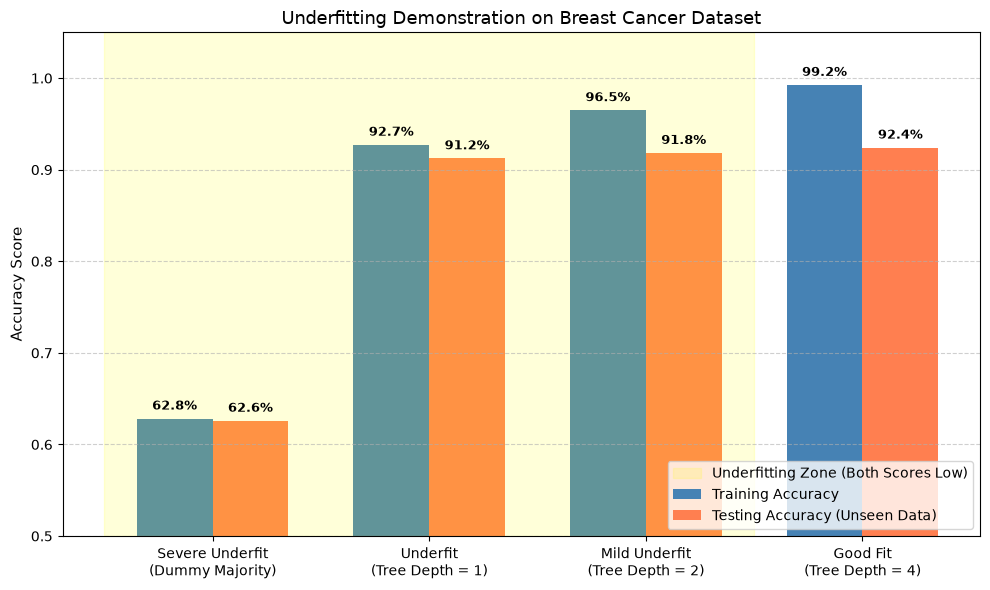

In [3]:
x = np.arange(len(names))
width = 0.35

plt.figure(figsize=(10, 6))

# Side-by-side bars for Training vs Testing Accuracy
bars1 = plt.bar(x - width/2, train_scores, width, label='Training Accuracy', color='steelblue')
bars2 = plt.bar(x + width/2, test_scores, width, label='Testing Accuracy (Unseen Data)', color='coral')

# Add percentage labels on top of each bar
for bar in bars1:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{bar.get_height()*100:.1f}%", ha='center', fontsize=9, fontweight='bold')
for bar in bars2:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{bar.get_height()*100:.1f}%", ha='center', fontsize=9, fontweight='bold')

# Highlight the Underfitting Zone
plt.axvspan(-0.5, 2.5, color='yellow', alpha=0.15, label='Underfitting Zone (Both Scores Low)')

plt.title('Underfitting Demonstration on Breast Cancer Dataset', fontsize=13)
plt.ylabel('Accuracy Score', fontsize=11)
plt.xticks(x, names, fontsize=10)
plt.ylim(0.50, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()